## Explorations into Biogeochemical Models

### Base Model

We use the model proposed by Hodges & Rudnick (2004) as our base:
$$
\begin{align}
    \frac{\partial N}{\partial t} &= -\mu(N,P,z) + \frac{\partial}{\partial z}\big( \kappa\frac{\partial N}{\partial z} \big), \\
    \frac{\partial P}{\partial t} &= \mu(N,P,z) + \frac{\partial}{\partial z}\big( \kappa\frac{\partial P}{\partial z} \big), \\
\end{align}
$$
with BCs:
$$
\begin{align}
    &\frac{\partial N}{\partial z} = \frac{\partial P}{\partial z} = 0 \textnormal{ at } z=0, \\
    &\frac{\partial N}{\partial z} = 0, \, P=0 \textnormal{ at } z=-\infty.
\end{align}
$$
Where:
- $N$: nutrients
- $P$: phytoplankton
- $\mu(N,P,z)$ is both:
    - Net rate at which nitrogen flows from $N$ to $P$
    - Net rate of total phytoplankton growth minus all losses (death and grazing by zooplankton included)
- $\kappa$: turbulent diffusivity

The function $\mu(N,P,z)$ is given as:
$$
\begin{align}
\mu(N,P,z) = GNPe^{Kz} - DP.
\end{align}
$$
Where:
- $G$: growth rate
- $D$: mortality rate
- $K$: light attenuation coefficient

#### Base Model Results

We can compare our time-dependent model results to the steady-state solution found in the paper:

In [1]:
# Just import statements and helper functions
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

%matplotlib ipympl

import sim, plots
from forcings import sine, pulses, ramp, add, seasonal_flux, constant

plt.rcParams["figure.figsize"] = (8, 4)
trapz = getattr(np, "trapezoid", None) or np.trapz       # depth integral

def dcm(res):
    """Depth and value of the phytoplankton maximum at every saved time."""
    k = res.P.argmax(axis=1)
    return res.depth[k], res.P[np.arange(len(k)), k]
    
# --- Plotting & animation ---
def draw_frame(frame, N, P, z):
    ax.clear()
    ax.plot(N[frame], z, label="Nutrients (N)")
    ax.plot(P[frame], z, label="Phytoplankton (P)")
    days = frame * 100 * 900 / 86400
    ax.set_title(f"Time: {days:.1f} Days")
    ax.set_xlabel("Concentration")
    ax.set_ylabel("Depth (m)")
    ax.legend(loc="upper right")
    ax.grid(True, linestyle="--", alpha=0.5)

#### Base Case Time Evolution of N and P

In [2]:
base = sim.run()
N, P, z = base.N, base.P, base.depth
# fig, ax = plt.subplots()
# anim = animation.FuncAnimation(fig=fig, func=draw_frame, fargs=(N, P, z), frames=520, interval=100, repeat=False)
# plt.show()

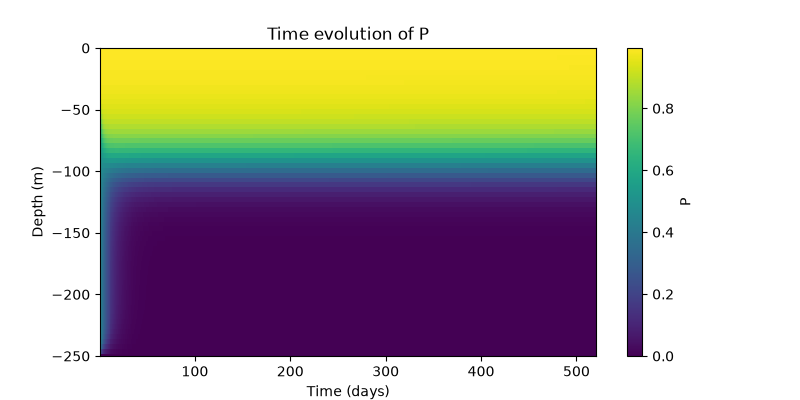

In [3]:
var="P"
plots.hovmoller(base, var, zmin=-250)
plt.title(f'Time evolution of {var}')
plt.show()

This figure gives us a good idea of the steady state, but doesn't tell us much about the evolution. This is because the steady state is reached very early.

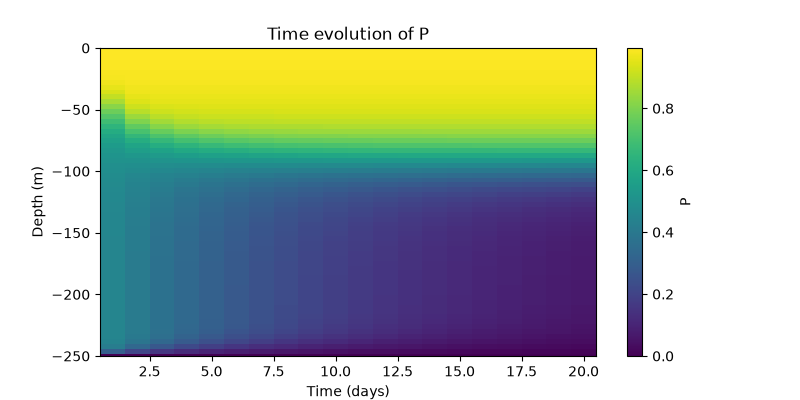

In [4]:
var="P"
plots.hovmoller(base, var, zmin=-250, max_day=20)
plt.title(f"Time evolution of {var}")
plt.show()

This is a decent toy model, but clearly not realistic (much like the toy population models we played with in the course earlier). So, we need to add some mroe terms to include some biology and physics that can occur. We do that in three different ways below. In each of them, we focus on both the time evolution and steady state (if one were to arise).

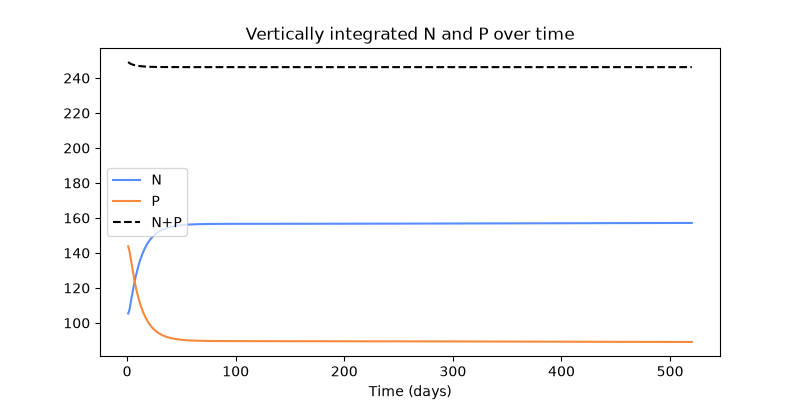

In [5]:
plots.integrated(base)
plt.title('Vertically integrated N and P over time')
plt.show()

### Phytoplankton sinking

One of the main aims of Hodges & Rudnick (2004) is to investigate possible mechanisms that cause the DCM (deep chlorophyll maximum) and DBM (deep biomass maximum) phenomena which is often seen in oceans. They conclude that phytoplankton sinking is critical to the formation of deep maxima in biomass in these models. For sinking, they add a sinking term to the equation for $P$ so that it becomes:
$$
\begin{align}
    \frac{\partial P}{\partial t} &= \mu(N,P,z) + \kappa\frac{\partial^2 P}{\partial z^2} - W\frac{\partial P}{\partial z}, \\
\end{align}
$$
with slightly modified BCs at the surface:
$$
\begin{align}
    &\kappa\frac{\partial N}{\partial z} = WP - \kappa\frac{\partial P}{\partial z} = 0 \textnormal{ at } z=0, \\
    &N=1, \, P=0 \textnormal{ at } z=-\infty.
\end{align}
$$



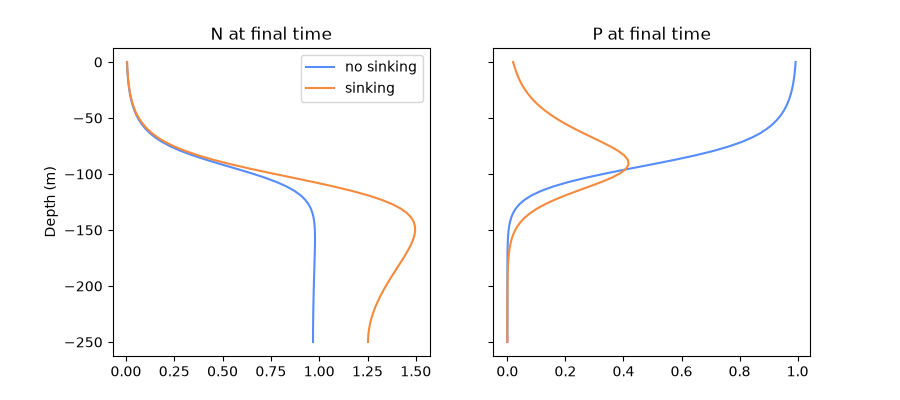

In [6]:
sink = sim.run(SINKING_ENABLED=True)

fig, ax = plt.subplots(1, 2, sharey=True, figsize=(9, 4))
for res, name in ((base, "no sinking"), (sink, "sinking")):
    ax[0].plot(res.N[-1], res.depth, label=name)
    ax[1].plot(res.P[-1], res.depth, label=name)
ax[0].set_title("N at final time"); ax[1].set_title("P at final time")
ax[0].set_ylabel("Depth (m)"); ax[0].legend()

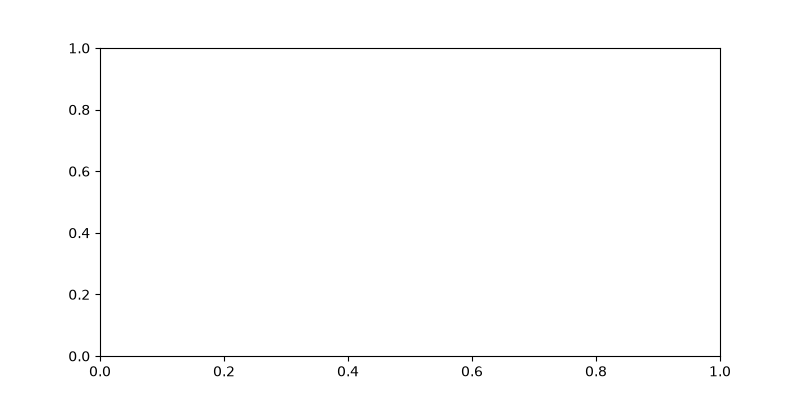

In [7]:
fig, ax = plt.subplots()
N, P, z = sink.N, sink.P, sink.depth
anim = animation.FuncAnimation(fig=fig, func=draw_frame, fargs=(N, P, z), frames=520, interval=100, repeat=False)
plt.show()

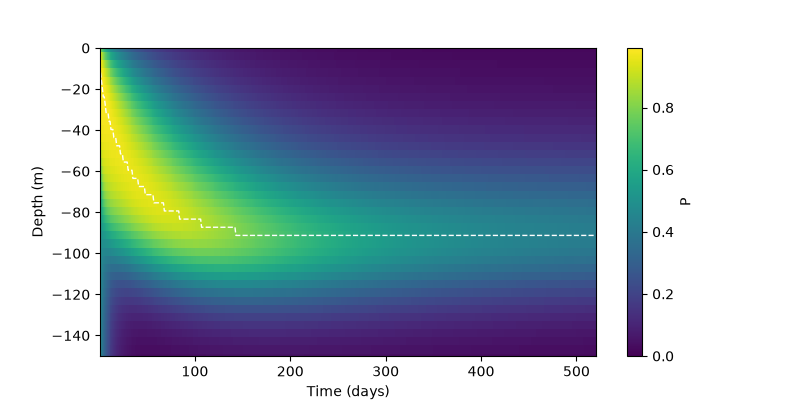

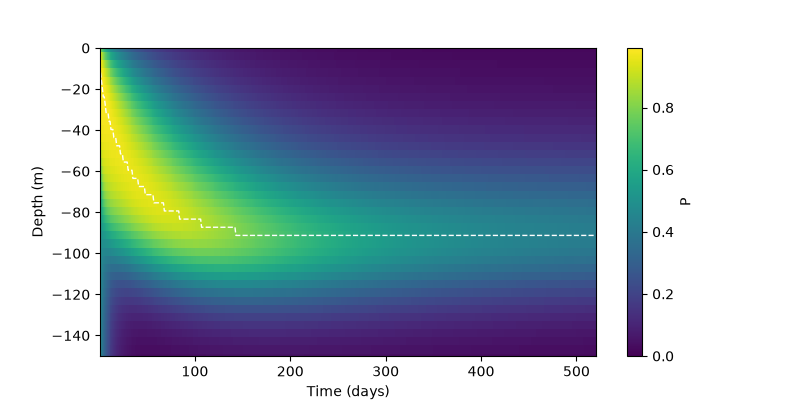

In [8]:
var = "P"
fig1, ax1 = plt.subplots()
plots.hovmoller(sink, "P", zmin=-150, fig=fig1, ax=ax1)
d, v = dcm(sink)
ax1.plot(sink.days, d, "w--", lw=1)                  # depth of the maximum
fig1.show()

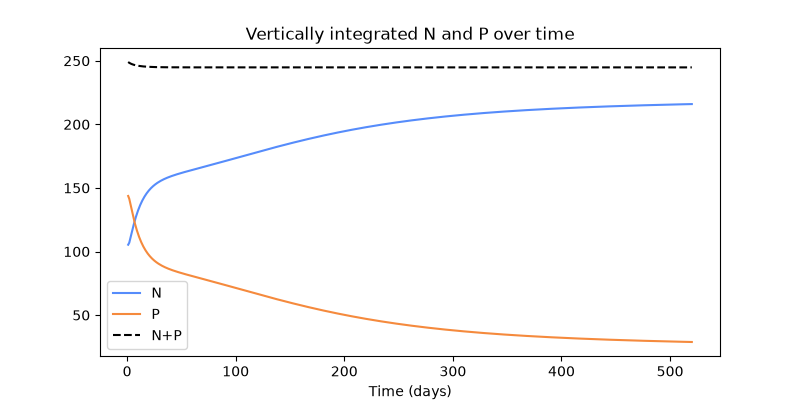

In [9]:
plots.integrated(sink)
plt.title('Vertically integrated N and P over time')
plt.show()

### Self-Shading by Phytoplankton

When phytoplankton stack on top of each other vertically, the deeper regions receive less light than shallower regions. This **self-shading** effect compounds the background exponential decay of light intensity in water according to the Beer-Lambert Law.

Recall, the 'growth' term includes an exponential light-decay factor:
$$
\begin{align}
\mu(N,P,z) = GNPe^{Kz} - DP.
\end{align}
$$
So far, we have considered $K$ to be constant. To model self-shading, we let $K$ depend on the phytoplankton concentration $P(z)$ in two ways:

### 1. (Levy, 2015)
The first one applies local attenuation
$$
\begin{align}
K = K_0 + K_s P,
\end{align}
$$
where $K_0$ is the background water attenuation coefficient used earlier, and $K_s$ is the specific attenuation due to phytoplankton. This assumes the water column above depth $z$ has a uniform concentration equal to $P(z)$.

### 2. (Shigesada and Okubo, 1981)
In this case, we modify the attenuation in a similar way, but now we include the vertically integrated phytoplankton above each depth level,
$$
\begin{align}
K = K_0 + \frac{K_s}{|z|}\int_{z}^0 P(z')dz' = K_0 + K_s \bar{P}(z),
\end{align}
$$
where $\bar{P}(z)$ is the average phytoplankton concentration above depth $z$.

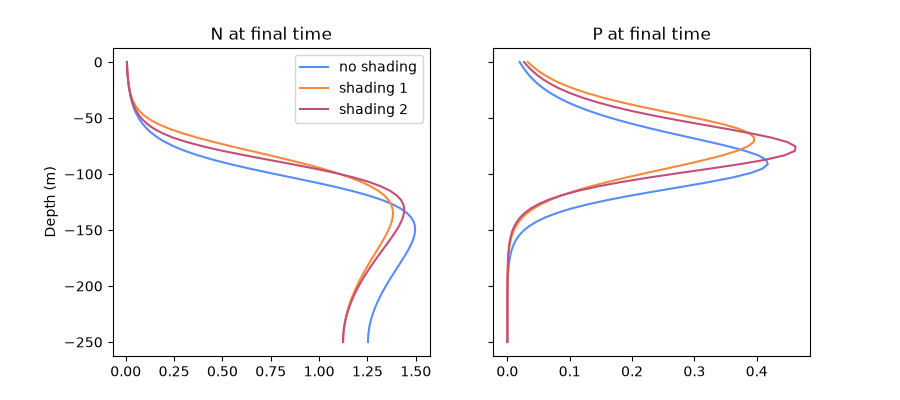

In [10]:
shade_local = sim.run(SINKING_ENABLED=True, SHADING_ENABLED=True, SHADING_MODE='local')
shade_integral = sim.run(SINKING_ENABLED=True, SHADING_ENABLED=True, SHADING_MODE='integral')

fig, ax = plt.subplots(1, 2, sharey=True, figsize=(9, 4))
for res, name in ((sink, "no shading"), (shade_local, "shading 1"), (shade_integral, "shading 2")):
    ax[0].plot(res.N[-1], res.depth, label=name)
    ax[1].plot(res.P[-1], res.depth, label=name)
ax[0].set_title("N at final time"); ax[1].set_title("P at final time")
ax[0].set_ylabel("Depth (m)"); ax[0].legend()

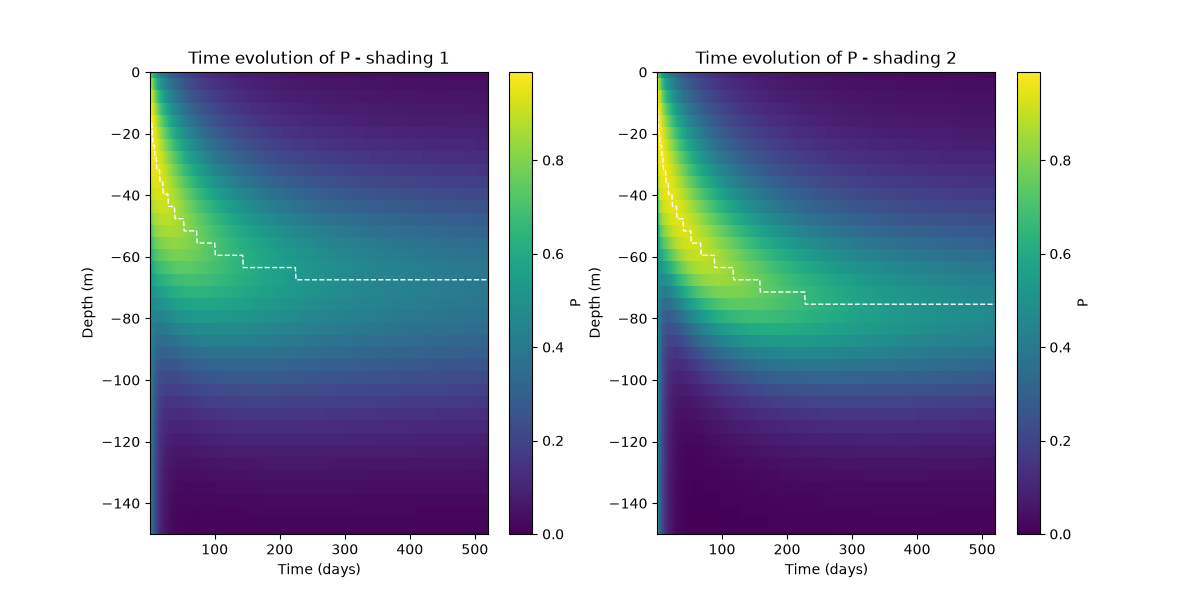

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

var = "P"
plots.hovmoller(shade_local, "P", zmin=-150, fig=fig, ax=ax[0])
d, v = dcm(shade_local)
ax[0].plot(shade_local.days, d, "w--", lw=1)                  # depth of the maximum
ax[0].set_title(f'Time evolution of {var} - shading 1')

var = "P"
plots.hovmoller(shade_integral, "P", zmin=-150, fig=fig, ax=ax[1])
d, v = dcm(shade_integral)
ax[1].plot(shade_integral.days, d, "w--", lw=1)                  # depth of the maximum
ax[1].set_title(f'Time evolution of {var} - shading 2')

plt.show()

### Forcing N

Finally, we want to investigate what happens when the nutrient flux at the surface is forced by some external agent. These situations can arise in real life due to various factors, such as river runoff (occurs seasonally), storm surges, or eutrophication. Below, we show different scenarios of nutrient flux forcings:

- Unforced / Constant: There is a constant addition of nutrients at the surface.
- Seasonal: The flux increases in the summer months once annually, modeling river runoff effects.
- Storm Pulse: A large influx of nutrients in a short time due storms.
- Eutrophication: The seasonal increase in the summer months but, this gets larger every year due to recycling of nutrients and depleted oxygen at the bottom.

In [12]:
F_REF = 1e-4 * 0.05                       # KAPPA * LIGHT_ATTENUATION (m s^-1 in nutrient units)
long = dict(DEPTH=500, NZ=127, T_END_DAYS=3 * 365, SAVE_EVERY_DAYS=5, SINKING_ENABLED=True, N_BOT_BC="dirichlet")

runs = {
    "unforced":             sim.run(**long),
    "constant":             sim.run(SURFACE_FLUX=constant(0.2*F_REF), **long),
    "seasonal flux":        sim.run(SURFACE_FLUX=seasonal_flux(0.2*F_REF, 0.2*F_REF), **long),
    "storm pulses":         sim.run(SURFACE_FLUX=pulses([100, 300, 500, 700], 1e-5, 2.0), **long),
    "eutrophication trend": sim.run(SURFACE_FLUX=add(seasonal_flux(0.2*F_REF, 0.2*F_REF), ramp(365, 1095, 0, 0.2*F_REF)), **long),
}

NameError: name 't' is not defined

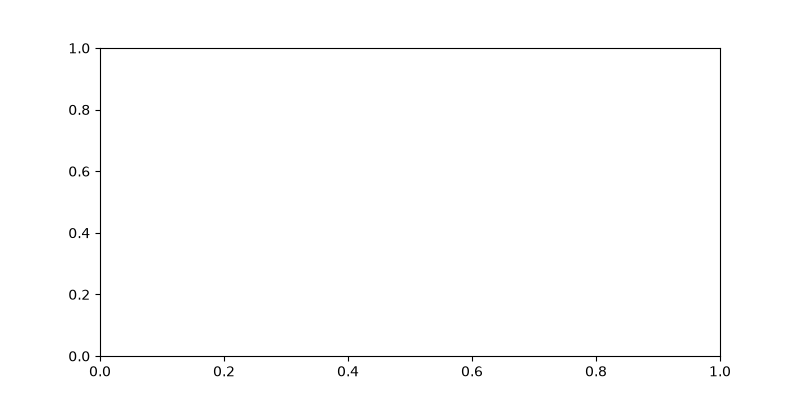

In [13]:
fig, ax = plt.subplots()
funcs = {
    'constant': constant(0.2*F_REF),
    'seasonal': seasonal_flux(0.2*F_REF, 0.2*F_REF),
    # 'storm': pulses(100, 1e-5, 2.0),
    'eutrophication': add(seasonal_flux(0.2*F_REF, 0.2*F_REF), ramp(365, 1095, 0, 0.2*F_REF))
}
times = np.arange(0, 365*3*86400, 1000)
for name, func in funcs.items():
    if name=='constant':
        ax.plot(times/86400, np.full_like(times, func(t)), label=name)
        continue
    ax.plot(times/86400, func(times), label=name)       
    ax.set_xlabel("Days")
    ax.set_ylabel("N Flux at surface")
ax.set_title("Nutrient Forcing Scenarios")
ax.grid(True, alpha=.3)
ax.legend()
plt.show()

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name, res in runs.items():
    ax[0].plot(res.days, res.P[:, -1], label=name)                 # surface P
    ax[1].plot(res.days, trapz(res.P, res.depth, axis=1), label=name)
ax[0].set_title("P at the surface"); ax[1].set_title("depth-integrated P")
for a in ax: a.set_xlabel("Time (days)"); a.grid(True, alpha=.3)
ax[0].legend()
plt.show()

In [ ]:
times = np.arange(0, 365*3*86400, 1000)
func = pulses([100, 300, 500, 700], 1e-5, 2.0)
seasonal = func(t)
print(func(t))
plt.figure()
# plt.plot(t, seasonal)
plt.show()

In [ ]:
func(t)

In [ ]:
t.shape